Dropped 0 rows with missing values
Building cross-basis for: Diurnal temperature range (°C)
Columns still containing NaN/Inf: ['Diurnal temperature range (°C)_cb0', 'Diurnal temperature range (°C)_cb1', 'Diurnal temperature range (°C)_cb2', 'Diurnal temperature range (°C)_cb3']
Dropping 4 rows with NaN/Inf

Final design matrix: (1247, 7)
Rank of X: 7  (should be close to 7)

Fitting pure Negative Binomial...
Optimization terminated successfully.
         Current function value: 3.911327
         Iterations: 50
         Function evaluations: 51
         Gradient evaluations: 51
                     NegativeBinomial Regression Results                      
Dep. Variable:                      y   No. Observations:                 1247
Model:               NegativeBinomial   Df Residuals:                     1240
Method:                           MLE   Df Model:                            6
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                0.004087
Time:                

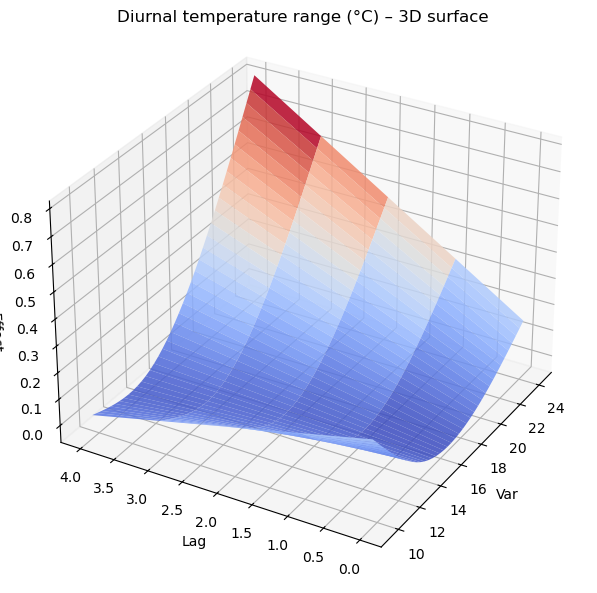

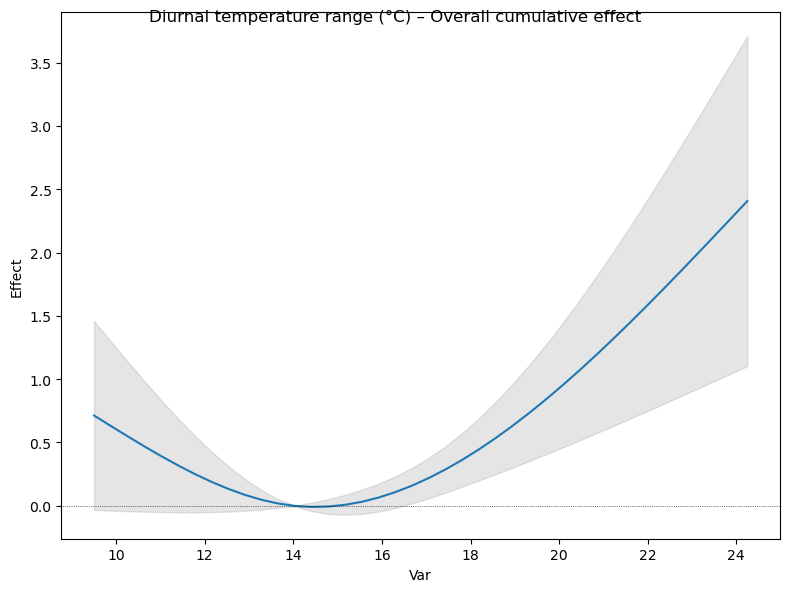

In [ ]:
"""
Stabilised DLNM pipeline for influenza counts
- Pure Negative Binomial (recommended)
- Zero-Inflated Negative Binomial (optional, more fragile)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple

import statsmodels.api as sm
from statsmodels.discrete.discrete_model import NegativeBinomial, Poisson
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP

from dlnm import crossbasis, crosspred, logknots, plot_crosspred


# ---------------------------------------------------------------------------
# 1. Data loading & cleaning
# ---------------------------------------------------------------------------

def load_and_prepare_data(
    filepath: str,
    outcome: str = "H1",
    date_col: str = "From",
) -> pd.DataFrame:
    df = pd.read_csv(filepath)
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.sort_values(date_col).reset_index(drop=True)



    # Basic time indices
    df["time"] = np.arange(len(df))
    df["year"] = df[date_col].dt.year
    df["week"] = df["Week"] if "Week" in df.columns else df[date_col].dt.isocalendar().week.astype(int)

    # Ensure outcome is clean
    df[outcome] = df[outcome].fillna(0).astype(int).clip(lower=0)

    # Meteorological columns
    meteo_cols = [
        "Diurnal temperature range (°C)",
        "Mean temperature (°C)",
        "Mean humidity (%)",
        "Solar radiation (MJ/m²)",
        "Air pressure (hPa)",
        "Dew point temperature (°C)",
        "Wind speed (km/h)",
        "Mean UV",
    ]
    for col in meteo_cols:
        if col in df.columns:
            df[col] = df[col].interpolate(method="linear").bfill().ffill()

    # Drop any remaining incomplete rows for the variables we will actually use
    keep_cols = [outcome] + [c for c in meteo_cols if c in df.columns]
    extra = ["pandemic_flag", "school_flag", "ContainmentHealthIndex_Average"]
    keep_cols += [c for c in extra if c in df.columns]

    n_before = len(df)
    df = df.dropna(subset=keep_cols).reset_index(drop=True)
    print(f"Dropped {n_before - len(df)} rows with missing values")

    # After loading and cleaning
    df["log_H1_lag1"] = np.log1p(df["H1"].shift(1))
    df = df.dropna().reset_index(drop=True)


    return df


# ---------------------------------------------------------------------------
# 2. Cross-basis (SIMPLER & MORE STABLE)
# ---------------------------------------------------------------------------

def build_crossbasis(
    exposure: np.ndarray,
    lag: int = 4,
    df_var: int = 2,
    df_lag: int = 2,
):
    """
    Build a cross-basis and keep the original CrossBasis object
    (required by crosspred / plot_crosspred).
    """
    exposure = np.asarray(exposure, dtype=float)
    if not np.isfinite(exposure).all():
        raise ValueError("Exposure still contains NaN/Inf after cleaning")

    cb = crossbasis(
        exposure,
        lag=lag,
        argvar={"fun": "ns", "df": df_var},
        arglag={"fun": "ns", "df": df_lag},
    )
    # IMPORTANT: do NOT convert to np.asarray – keep the CrossBasis object
    return cb


def build_multiple_crossbases(
    df: pd.DataFrame,
    exposures: List[str],
    lag: int = 6,
    df_var: int = 3,
    df_lag: int = 3,
) -> Dict[str, object]:
    cbs = {}
    for exp in exposures:
        print(f"Building cross-basis for: {exp}")
        cbs[exp] = build_crossbasis(
            df[exp].values,
            lag=lag,
            df_var=df_var,
            df_lag=df_lag,
        )
    return cbs

# ---------------------------------------------------------------------------
# 3. Design matrix
# ---------------------------------------------------------------------------

def make_design_matrix(
    df: pd.DataFrame,
    crossbases: dict,
    covariates: list | None = None,
    add_intercept: bool = True,
    add_time_trend: bool = True,
    seasonality_df: int = 0,
):
    """
    Build the design matrix and return (X, colnames).
    """
    pieces = []
    colnames = []

    # Intercept
    if add_intercept:
        pieces.append(np.ones((len(df), 1)))
        colnames.append("Intercept")

    # Cross-bases (convert to array only here)
    for name, cb in crossbases.items():
        cb_array = np.asarray(cb, dtype=float)
        pieces.append(cb_array)
        colnames.extend([f"{name}_cb{i}" for i in range(cb_array.shape[1])])

    # Extra covariates
    if covariates:
        for cov in covariates:
            if cov in df.columns:
                pieces.append(df[cov].values.reshape(-1, 1))
                colnames.append(cov)

    # Seasonality
    if seasonality_df > 0:
        from patsy import dmatrix
        week = df["week"].values
        seas = np.asarray(dmatrix(f"cr(week, df={seasonality_df}) - 1", {"week": week}))
        pieces.append(seas)
        colnames.extend([f"seas{i}" for i in range(seas.shape[1])])

    # Time trend (scaled for numerical stability)
    if add_time_trend:
        pieces.append((df["time"].values.reshape(-1, 1) / 100.0))
        colnames.append("time")

    # ---- THIS LINE WAS PROBABLY MISSING OR INDENTED WRONGLY ----
    X = np.column_stack(pieces)
    return X, colnames

def clean_design_matrix(y, X, colnames=None):
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)

    bad_cols = ~np.isfinite(X).all(axis=0)
    if bad_cols.any():
        if colnames is not None:
            print("Columns still containing NaN/Inf:",
                  [colnames[i] for i in np.where(bad_cols)[0]])
        else:
            print("Bad column indices:", np.where(bad_cols)[0])

    good = np.isfinite(y) & np.isfinite(X).all(axis=1)
    n_drop = (~good).sum()
    if n_drop:
        print(f"Dropping {n_drop} rows with NaN/Inf")
    return y[good], X[good]


# ---------------------------------------------------------------------------
# 4. Model fitting (more robust)
# ---------------------------------------------------------------------------

def fit_negative_binomial(y, X, maxiter=1000):
    """Pure Negative Binomial – recommended starting point."""
    model = NegativeBinomial(y, X, loglike_method="nb2")

    # Good starting values from Poisson
    try:
        start = Poisson(y, X).fit(disp=False).params
        start = np.append(start, 0.5)          # alpha
    except Exception:
        start = None

    res = model.fit(
        start_params=start,
        method="bfgs",
        maxiter=maxiter,
        disp=True,
        cov_type="HC0",
    )
    return res


def fit_zero_inflated_nb(y, X, maxiter=1500):
    """
    Zero-Inflated NB – more fragile.
    Only use after pure NB is working cleanly.
    """
    model = ZeroInflatedNegativeBinomialP(y, X, inflation="logit", p=2)

    res = model.fit(
        method="bfgs",
        maxiter=maxiter,
        disp=True,
        cov_type="HC0",
    )
    return res


# ---------------------------------------------------------------------------
# 5. Coefficient extraction & plotting
# ---------------------------------------------------------------------------

def extract_cb_coefficients(result, cb_start: int, cb_end: int):
    coef = np.asarray(result.params[cb_start:cb_end])

    cov = result.cov_params()
    if hasattr(cov, "iloc"):
        vcov = cov.iloc[cb_start:cb_end, cb_start:cb_end].values
    else:
        vcov = np.asarray(cov)[cb_start:cb_end, cb_start:cb_end]

    return coef, vcov


def plot_exposure_lag_response(cb, coef, vcov, at=None, cen=None, title=""):
    pred = crosspred(cb0, coef=coef, vcov=vcov, at=at, cen=cen)

    fig1 = plot_crosspred(pred, ptype="3d")
    fig1.suptitle(f"{title} – 3D surface")

    fig2 = plot_crosspred(pred, ptype="overall")
    fig2.suptitle(f"{title} – Overall cumulative effect")

    return pred, fig1, fig2


# ---------------------------------------------------------------------------
# 6. Main pipeline
# ---------------------------------------------------------------------------

def run_dlnm_pipeline(
    filepath: str,
    outcome: str = "H1",
    exposures: Optional[List[str]] = None,
    lag: int = 6,
    covariates: Optional[List[str]] = None,
    use_zinb: bool = False,          # keep False until NB works
    df_var: int = 3,
    df_lag: int = 3,
):
    if exposures is None:
        exposures = ["Mean temperature (°C)", "Mean humidity (%)"]

    if covariates is None:
        covariates = ["pandemic_flag", "school_flag", "H1_lag1"]

    # 1. Load
    df = load_and_prepare_data(filepath, outcome=outcome)
    y = df[outcome].values

    # Force finite values and mild winsorising to avoid extreme basis values
    col = "Diurnal temperature range (°C)"
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    df[col] = df[col].interpolate().bfill().ffill()

    # Optional: winsorise extreme tails
    low, high = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(low, high)

    # 2. Cross-bases (simpler)
    cbs = build_multiple_crossbases(
        df, exposures, lag=lag, df_var=df_var, df_lag=df_lag
    )

    # 3. Design matrix
    X, colnames = make_design_matrix(
        df,
        crossbases=cbs,
        covariates=covariates,
        add_intercept=True,
        add_time_trend=False,
        seasonality_df=0,
    )

    y, X = clean_design_matrix(y, X, colnames)

    print(f"\nFinal design matrix: {X.shape}")
    print(f"Rank of X: {np.linalg.matrix_rank(X)}  (should be close to {X.shape[1]})")

    # 4. Fit
    if use_zinb:
        print("\nFitting Zero-Inflated Negative Binomial...")
        res = fit_zero_inflated_nb(y, X)
    else:
        print("\nFitting pure Negative Binomial...")
        res = fit_negative_binomial(y, X)

    print(res.summary())
    return df, cbs, X, colnames, res, y


# ---------------------------------------------------------------------------
# 7. Typical usage
# ---------------------------------------------------------------------------

CSV_PATH = "data.csv"

# ---------- RECOMMENDED: start with pure Negative Binomial ----------
df, cbs, X, colnames, res, y = run_dlnm_pipeline(
    filepath=CSV_PATH,
    outcome="H1",
    exposures=["Diurnal temperature range (°C)", "Dew point temperature (°C)"],
    lag=4,
    covariates = ["pandemic_flag", "school_flag", "H1_lag1"],
    use_zinb=False,          # ← keep False for now
    df_var=2,
    df_lag=2,
)

# ---------- Only try ZINB after the above works cleanly ----------
#df, cbs, X, colnames, res, y = run_dlnm_pipeline(
#     filepath=CSV_PATH,
#     outcome="H1",
#     exposures=["Diurnal temperature range (°C)"],
#     lag=6,
#     use_zinb=True,
#)

# ---------- Plot the first exposure ----------
first_exp = list(cbs.keys())[0]
cb0 = cbs[first_exp]
n_cb0 = cb0.shape[1]

# Intercept is column 0 → cross-basis starts at 1
start = 1
end = start + n_cb0

coef, vcov = extract_cb_coefficients(res, start, end)

pred, fig3d, fig_overall = plot_exposure_lag_response(
    cb=cb0,
    coef=coef,
    vcov=vcov,
    at=np.linspace(df[first_exp].min(), df[first_exp].max(), 40),
    cen=df[first_exp].median(),
    title=first_exp,
)

plt.show()

MODEL SUMMARY
                     NegativeBinomial Regression Results                      
Dep. Variable:                      y   No. Observations:                 1247
Model:               NegativeBinomial   Df Residuals:                     1240
Method:                           MLE   Df Model:                            6
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                0.004087
Time:                        18:48:33   Log-Likelihood:                -4877.4
converged:                       True   LL-Null:                       -4897.4
Covariance Type:                  HC0   LLR p-value:                 4.481e-07
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.5178      0.306     14.772      0.000       3.918       5.117
x1            -0.2352      0.267     -0.882      0.378      -0.758       0.287
x2             0.6354      0.640      

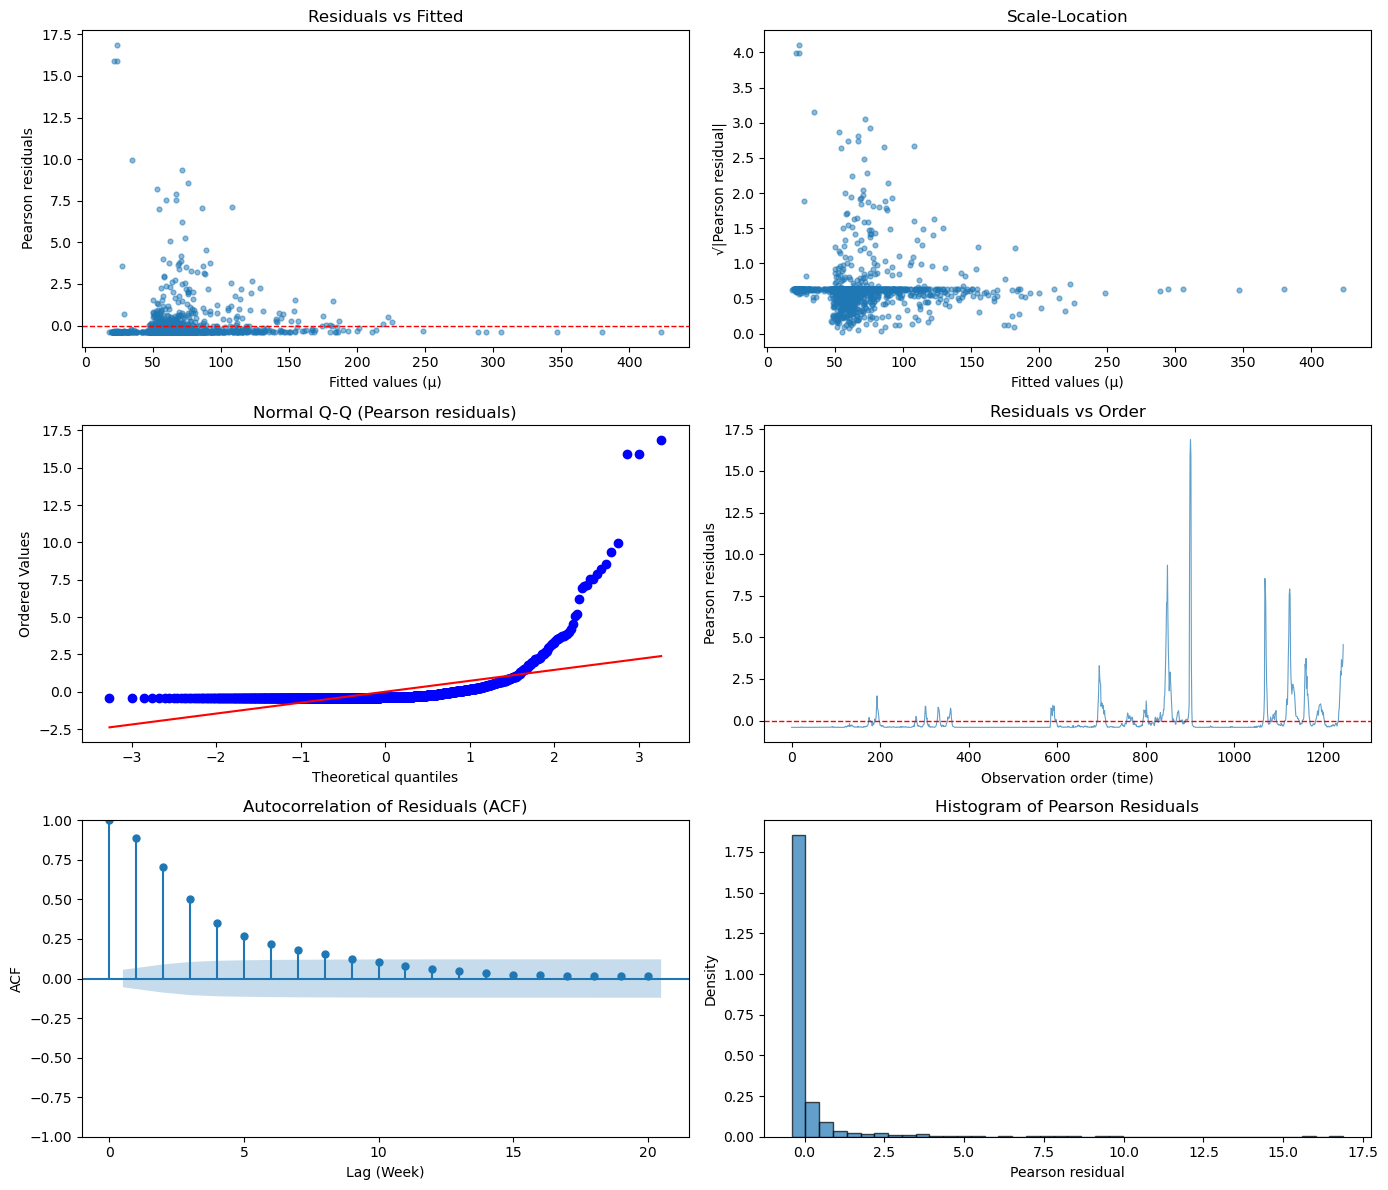

In [51]:
# ===========================================================================
# Result diagnostics 
# ===========================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.tsaplots import plot_acf


def compute_residuals(result, y, X):
    """Compute several residual types for a count model."""
    mu = np.asarray(result.predict(X)).ravel()
    y = np.asarray(y).ravel()

    resid_response = y - mu

    # Pearson residual (NB2 variance if possible)
    alpha = getattr(result, "alpha", None)
    if alpha is None:
        lnalpha = getattr(result, "lnalpha", None)
        alpha = np.exp(lnalpha) if lnalpha is not None else 0.0

    var = mu + alpha * mu**2 if alpha > 0 else mu
    resid_pearson = resid_response / np.sqrt(var + 1e-8)

    # Approximate deviance residual
    with np.errstate(divide="ignore", invalid="ignore"):
        dev = np.where(
            y == 0,
            2 * mu,
            2 * (y * np.log((y + 1e-8) / (mu + 1e-8)) - (y - mu)),
        )
    resid_deviance = np.sign(y - mu) * np.sqrt(np.maximum(dev, 0.0))

    return {
        "fitted": mu,
        "response": resid_response,
        "pearson": resid_pearson,
        "deviance": resid_deviance,
    }


def residual_diagnostics_plots(result, y, X, figsize=(14, 12)):
    """
    Residual diagnostic plots including ACF of residuals.
    """
    resids = compute_residuals(result, y, X)
    mu = resids["fitted"]
    pearson = resids["pearson"]

    fig, axes = plt.subplots(3, 2, figsize=figsize)

    # 1. Residuals vs Fitted
    axes[0, 0].scatter(mu, pearson, alpha=0.5, s=12)
    axes[0, 0].axhline(0, color="red", ls="--", lw=1)
    axes[0, 0].set_xlabel("Fitted values (μ)")
    axes[0, 0].set_ylabel("Pearson residuals")
    axes[0, 0].set_title("Residuals vs Fitted")

    # 2. Scale-Location
    axes[0, 1].scatter(mu, np.sqrt(np.abs(pearson)), alpha=0.5, s=12)
    axes[0, 1].set_xlabel("Fitted values (μ)")
    axes[0, 1].set_ylabel("√|Pearson residual|")
    axes[0, 1].set_title("Scale-Location")

    # 3. Normal Q-Q
    stats.probplot(pearson, dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title("Normal Q-Q (Pearson residuals)")

    # 4. Residuals vs Order (time)
    axes[1, 1].plot(pearson, alpha=0.7, lw=0.8)
    axes[1, 1].axhline(0, color="red", ls="--", lw=1)
    axes[1, 1].set_xlabel("Observation order (time)")
    axes[1, 1].set_ylabel("Pearson residuals")
    axes[1, 1].set_title("Residuals vs Order")

    # 5. ACF of Pearson residuals (the plot you requested)
    plot_acf(pearson, lags=20, ax=axes[2, 0], title="Autocorrelation of Residuals (ACF)")
    axes[2, 0].set_xlabel("Lag (Week)")
    axes[2, 0].set_ylabel("ACF")

    # 6. Histogram of residuals
    axes[2, 1].hist(pearson, bins=40, density=True, alpha=0.7, edgecolor="black")
    axes[2, 1].set_xlabel("Pearson residual")
    axes[2, 1].set_ylabel("Density")
    axes[2, 1].set_title("Histogram of Pearson Residuals")

    plt.tight_layout()
    return fig, resids


def overdispersion_check(result, y, X):
    """Simple overdispersion statistics."""
    resids = compute_residuals(result, y, X)
    n = len(y)
    p = X.shape[1]

    pearson_chi2 = np.sum(resids["pearson"] ** 2)
    resid_dev = np.sum(resids["deviance"] ** 2)

    return {
        "n_obs": n,
        "n_params": p,
        "pearson_chi2": pearson_chi2,
        "pearson_chi2 / df": pearson_chi2 / (n - p),
        "deviance": resid_dev,
        "deviance / df": resid_dev / (n - p),
    }


def vif_table(X, colnames=None, top=15):
    """Variance Inflation Factors."""
    X = np.asarray(X, dtype=float)
    vifs = []
    for i in range(X.shape[1]):
        try:
            vifs.append(variance_inflation_factor(X, i))
        except Exception:
            vifs.append(np.nan)

    names = colnames if colnames is not None else [f"x{i}" for i in range(X.shape[1])]
    df_vif = pd.DataFrame({"variable": names, "VIF": vifs})
    return df_vif.sort_values("VIF", ascending=False).head(top)


def run_diagnostics(result, y, X, colnames=None, plot=True):
    """
    Full diagnostics including ACF of residuals.
    """
    print("=" * 65)
    print("MODEL SUMMARY")
    print("=" * 65)
    print(result.summary())

    print("\n" + "=" * 65)
    print("OVERDISPERSION / GOODNESS-OF-FIT")
    print("=" * 65)
    od = overdispersion_check(result, y, X)
    for k, v in od.items():
        print(f"{k:25s}: {v:.4f}" if isinstance(v, float) else f"{k:25s}: {v}")

    print("\n" + "=" * 65)
    print("VARIANCE INFLATION FACTORS (top 15)")
    print("=" * 65)
    vif_df = vif_table(X, colnames)
    print(vif_df.to_string(index=False))

    if plot:
        print("\nGenerating residual diagnostic plots (including ACF)...")
        fig, resids = residual_diagnostics_plots(result, y, X)
        plt.show()
        return {"overdispersion": od, "vif": vif_df, "residuals": resids, "fig": fig}

    return {"overdispersion": od, "vif": vif_df}


# ===========================================================================
# Usage (after the pipeline)
# ===========================================================================


# or reconstruct:
# y_full = df["H1"].values
# y, X = clean_design_matrix(y_full, X, colnames)

diag = run_diagnostics(
    result=res,
    y=y,                # must have same length as X
    X=X,
    colnames=colnames,
    plot=True,
)

In [52]:
print("Rank of X:", np.linalg.matrix_rank(X))
print("Number of columns:", X.shape[1])
print("Condition number:", np.linalg.cond(X.T @ X))
print(res.mle_retvals)          # check 'converged'

Rank of X: 7
Number of columns: 7
Condition number: 171.969394603319
{'fopt': np.float64(3.9113269283307535), 'gopt': array([ 3.75938470e-07, -2.34182613e-06, -7.01931969e-07, -1.92672869e-06,
        8.75776814e-06,  1.38355545e-06, -5.05833151e-07, -2.39216809e-06]), 'Hinv': array([[ 1.02765007e+02, -5.89001775e+01, -3.58447821e+01,
         4.22294875e+01, -1.09727057e+01,  2.88108092e+01,
        -3.45804158e+01,  6.29017122e-01],
       [-5.89001775e+01,  6.32214310e+01,  2.78221141e+01,
        -2.41640654e+01, -1.71327858e+01, -2.31710781e+01,
        -1.02401888e+01, -4.91153688e-01],
       [-3.58447821e+01,  2.78221141e+01,  3.32807043e+02,
        -2.81205248e+01,  7.26997216e+01, -3.41717529e+01,
        -2.09128142e+01,  2.04275238e-01],
       [ 4.22294875e+01, -2.41640654e+01, -2.81205248e+01,
         7.82137632e+01,  2.67750077e+00,  2.25385819e+01,
        -3.96409271e+00, -2.14376676e-01],
       [-1.09727057e+01, -1.71327858e+01,  7.26997216e+01,
         2.67750077

In [54]:
# 1. Look at the linear predictor
linpred = res.predict(X, which="linear")   # or res.model.predict(res.params, X, which="linear")
print("Linear predictor: min / max / mean")
print(linpred.min(), linpred.max(), linpred.mean())

# 2. Check the AR term
print("\nH1_lag1 stats:")
print(df["log_H1_lag1"].describe())

# 3. Check which columns are extreme
print("\nMax absolute value per column in X:")
for i, name in enumerate(colnames):
    print(f"{name:40s}: {np.abs(X[:, i]).max():.3f}")

Linear predictor: min / max / mean
2.884347883829408 6.048439667975842 4.149140831497624

H1_lag1 stats:
count    1251.000000
mean        2.079697
std         2.113512
min         0.000000
25%         0.000000
50%         1.609438
75%         3.860674
max         7.600902
Name: log_H1_lag1, dtype: float64

Max absolute value per column in X:
Intercept                               : 1.000
Diurnal temperature range (°C)_cb0      : 1.418
Diurnal temperature range (°C)_cb1      : 0.581
Diurnal temperature range (°C)_cb2      : 1.698
Diurnal temperature range (°C)_cb3      : 0.975
pandemic_flag                           : 1.000
school_flag                             : 1.000
